# Лабораторная работа №1–2
## Экономика информатизации
### Оценка экономической эффективности внедрения облачной CRM

**Задача.** Компания «ТехноПром» рассматривает вопрос о внедрении облачной CRM-системы для отдела продаж.
Нужно оценить прямой эффект, затраты на внедрение, финансовые показатели эффективности (NPV, срок окупаемости, ROI)
и проанализировать нематериальные эффекты.

## 1. Исходные данные

| Параметр | Значение |
|---|---|
| Количество менеджеров в отделе продаж | 15 чел. |
| Средняя зарплата менеджера | 120 000 руб./мес. |
| Экономия времени на рутинных операциях после внедрения CRM | 20% |
| Процент рабочего времени, тратимый на рутинные операции (без CRM) | 30% |
| Рост продаж после внедрения CRM (умеренный прогноз) | 8% в год |
| Текущий годовой оборот отдела продаж | 72 млн руб. |
| Стоимость облачной CRM на год (на пользователя) | 24 000 руб./чел. |
| Время на обучение внедрению CRM (потеря на адаптацию) | 1 месяц |
| Горизонт оценки | 3 года |
| Ставка дисконтирования | 12% |
| Налог на прибыль | 20% |

In [1]:
# Исходные данные
n_managers = 15                # количество менеджеров
salary_month = 120_000         # средняя зарплата менеджера, руб./мес.
time_saving_pct = 0.20         # экономия времени на рутинных операциях после CRM
routine_pct = 0.30             # доля рабочего времени на рутинные операции (без CRM)
sales_growth = 0.08            # рост продаж после внедрения CRM, в год
turnover0 = 72_000_000         # текущий годовой оборот отдела продаж, руб.
license_per_user = 24_000      # стоимость CRM на пользователя в год, руб.
training_months = 1            # время на обучение (адаптацию), мес.
horizon = 3                    # горизонт оценки, лет
r = 0.12                       # ставка дисконтирования
tax_rate = 0.20                # налог на прибыль

annual_salary_fund = n_managers * salary_month * 12
monthly_salary_fund = n_managers * salary_month

print(f"Годовой ФОТ отдела продаж: {annual_salary_fund:,.0f} руб.".replace(",", " "))
print(f"Месячный ФОТ отдела продаж: {monthly_salary_fund:,.0f} руб.".replace(",", " "))

Годовой ФОТ отдела продаж: 21 600 000 руб.
Месячный ФОТ отдела продаж: 1 800 000 руб.


## 2. Прямой эффект от внедрения CRM

### 2.1. Экономия на заработной плате за счёт автоматизации рутинных операций

Доля высвобождаемого рабочего времени = доля времени на рутинные операции × экономия этого времени после CRM:

$$\text{Доля высвобожд. времени} = \text{routine\_pct} \times \text{time\_saving\_pct}$$

Годовая экономия = годовой ФОТ × доля высвобождаемого времени.

In [2]:
freed_time_share = routine_pct * time_saving_pct
salary_savings_annual = annual_salary_fund * freed_time_share

print(f"Доля высвобождаемого времени: {freed_time_share:.1%}")
print(f"Годовая экономия на ФОТ: {salary_savings_annual:,.0f} руб./год".replace(",", " "))

Доля высвобождаемого времени: 6.0%
Годовая экономия на ФОТ: 1 296 000 руб./год


### 2.2. Дополнительный доход от роста продаж

Рост продаж применяется кумулятивно (накопительным итогом) к обороту отдела продаж на протяжении горизонта оценки:

$$\text{Оборот}_t = \text{Оборот}_{t-1} \times (1 + \text{sales\_growth})$$

In [3]:
turnover = [turnover0]
for _ in range(horizon):
    turnover.append(turnover[-1] * (1 + sales_growth))

sales_increments = [turnover[i + 1] - turnover[i] for i in range(horizon)]

print(f"{'Год':>5} | {'Оборот, руб.':>15} | {'Прирост, руб.':>15}")
print(f"{0:>5} | {turnover[0]:>15,.0f} | {'—':>15}".replace(",", " "))
for i in range(horizon):
    print(f"{i+1:>5} | {turnover[i+1]:>15,.0f} | {sales_increments[i]:>15,.0f}".replace(",", " "))

  Год |    Оборот, руб. |   Прирост, руб.
    0 |      72 000 000 |               —
    1 |      77 760 000 |       5 760 000
    2 |      83 980 800 |       6 220 800
    3 |      90 699 264 |       6 718 464


## 3. Затраты на внедрение

### 3.1. Стоимость лицензий за 3 года

In [4]:
license_annual = n_managers * license_per_user
license_3y = license_annual * horizon

print(f"Лицензии в год: {license_annual:,.0f} руб./год".replace(",", " "))
print(f"Лицензии за {horizon} года: {license_3y:,.0f} руб.".replace(",", " "))

Лицензии в год: 360 000 руб./год
Лицензии за 3 года: 1 080 000 руб.


### 3.2. Потери от снижения производительности в первый месяц обучения

**Допущение:** в течение месяца адаптации менеджеры теряют часть продуктивности — принимаем, что потеря эквивалентна
тому же проценту (20%), на который в дальнейшем экономится рабочее время, применённому к месячному ФОТ отдела.
Эти потери считаются единовременными затратами в момент начала проекта (t = 0).

In [5]:
training_loss = monthly_salary_fund * time_saving_pct

print(f"Потери на обучении (единовременно): {training_loss:,.0f} руб.".replace(",", " "))

Потери на обучении (единовременно): 360 000 руб.


## 4. Финансовые показатели эффективности

### 4.1. Прирост чистой прибыли по годам (с учётом налога на прибыль 20%)

Единовременные потери на обучении учтены как первоначальные затраты (I₀) в момент t = 0,
стоимость лицензий — как ежегодные операционные расходы.

In [6]:
I0 = training_loss  # первоначальные затраты (обучение), момент t = 0

pretax_profit = []
for yr in range(horizon):
    val = salary_savings_annual + sales_increments[yr] - license_annual
    pretax_profit.append(val)

tax = [p * tax_rate for p in pretax_profit]
net_profit = [p - t for p, t in zip(pretax_profit, tax)]

header = f"{'Показатель':<32}" + "".join(f"{'Год ' + str(i+1):>16}" for i in range(horizon))
print(header)
print(f"{'Экономия на ФОТ, руб.':<32}" + "".join(f"{salary_savings_annual:>16,.0f}" for _ in range(horizon)).replace(",", " "))
print(f"{'Доход от роста продаж, руб.':<32}" + "".join(f"{v:>16,.0f}" for v in sales_increments).replace(",", " "))
print(f"{'Стоимость лицензий, руб.':<32}" + "".join(f"{-license_annual:>16,.0f}" for _ in range(horizon)).replace(",", " "))
print(f"{'Прибыль до налога, руб.':<32}" + "".join(f"{v:>16,.0f}" for v in pretax_profit).replace(",", " "))
print(f"{'Налог на прибыль (20%), руб.':<32}" + "".join(f"{-v:>16,.0f}" for v in tax).replace(",", " "))
print(f"{'Прирост чистой прибыли, руб.':<32}" + "".join(f"{v:>16,.0f}" for v in net_profit).replace(",", " "))
print()
print(f"Первоначальные затраты I0 (обучение, t=0): {I0:,.0f} руб.".replace(",", " "))

Показатель                                 Год 1           Год 2           Год 3
Экономия на ФОТ, руб.                  1 296 000       1 296 000       1 296 000
Доход от роста продаж, руб.            5 760 000       6 220 800       6 718 464
Стоимость лицензий, руб.                -360 000        -360 000        -360 000
Прибыль до налога, руб.                6 696 000       7 156 800       7 654 464
Налог на прибыль (20%), руб.          -1 339 200      -1 431 360      -1 530 893
Прирост чистой прибыли, руб.           5 356 800       5 725 440       6 123 571

Первоначальные затраты I0 (обучение  t=0): 360 000 руб.


### 4.2. NPV проекта (ставка дисконтирования r = 12%)

$$NPV = -I_0 + \sum_{t=1}^{3} \frac{CF_t}{(1+r)^t}$$

In [7]:
discount_factors = [1 / (1 + r) ** (t + 1) for t in range(horizon)]
discounted_cf = [net_profit[t] * discount_factors[t] for t in range(horizon)]

print(f"{'Год':>5} | {'CF, руб.':>14} | {'Коэфф. дисконт.':>16} | {'Дисконт. поток, руб.':>20}")
print(f"{0:>5} | {-I0:>14,.0f} | {1.0:>16.4f} | {-I0:>20,.0f}".replace(",", " "))
for t in range(horizon):
    print(f"{t+1:>5} | {net_profit[t]:>14,.0f} | {discount_factors[t]:>16.4f} | {discounted_cf[t]:>20,.0f}".replace(",", " "))

NPV = -I0 + sum(discounted_cf)
print(f"\nNPV = {NPV:,.0f} руб.".replace(",", " "))
print("Проект экономически выгоден" if NPV > 0 else "Проект экономически невыгоден")

  Год |       CF, руб. |  Коэфф. дисконт. | Дисконт. поток, руб.
    0 |       -360 000 |           1.0000 |             -360 000
    1 |      5 356 800 |           0.8929 |            4 782 857
    2 |      5 725 440 |           0.7972 |            4 564 286
    3 |      6 123 571 |           0.7118 |            4 358 637

NPV = 13 345 780 руб.
Проект экономически выгоден


### 4.3. Простой срок окупаемости

$$T_{ок} = \frac{I_0}{CF_1}$$

(предполагается равномерное поступление денежного потока в течение года)

In [8]:
payback_years = I0 / net_profit[0]
payback_months = payback_years * 12

print(f"Срок окупаемости: {payback_years:.3f} года ≈ {payback_months:.2f} месяца (≈ {payback_months*30:.0f} дней)")

Срок окупаемости: 0.067 года ≈ 0.81 месяца (≈ 24 дней)


### 4.4. ROI проекта

$$ROI = \frac{\text{Суммарный эффект} - \text{Суммарные затраты}}{\text{Суммарные затраты}} \times 100\%$$

In [9]:
total_costs = I0 + license_3y
total_net_benefit = sum(net_profit)
roi = (total_net_benefit - total_costs) / total_costs * 100

print(f"Суммарные затраты (обучение + лицензии за {horizon} года): {total_costs:,.0f} руб.".replace(",", " "))
print(f"Суммарный прирост чистой прибыли за {horizon} года: {total_net_benefit:,.0f} руб.".replace(",", " "))
print(f"ROI проекта: {roi:.1f}%")

Суммарные затраты (обучение + лицензии за 3 года): 1 440 000 руб.
Суммарный прирост чистой прибыли за 3 года: 17 205 811 руб.
ROI проекта: 1094.8%


### Визуализация: чистый денежный поток по годам

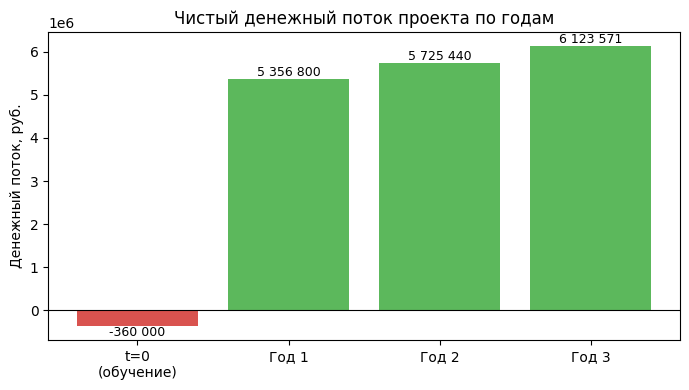

In [10]:
import matplotlib.pyplot as plt

years = ["t=0\n(обучение)"] + [f"Год {i+1}" for i in range(horizon)]
flows = [-I0] + net_profit
colors = ["#d9534f" if v < 0 else "#5cb85c" for v in flows]

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(years, flows, color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Денежный поток, руб.")
ax.set_title("Чистый денежный поток проекта по годам")
for i, v in enumerate(flows):
    ax.text(i, v, f"{v:,.0f}".replace(",", " "), ha="center",
             va="bottom" if v >= 0 else "top", fontsize=9)
plt.tight_layout()
plt.show()

## 5. Нематериальные эффекты

### 5.1. Нематериальные выгоды от внедрения CRM

- Повышение качества обслуживания клиентов и рост удовлетворённости за счёт единой истории взаимодействий.
- Снижение риска потери клиентов и сделок при увольнении/замене менеджера — данные остаются в системе, а не в личных записях сотрудника.
- Более точная и прозрачная аналитика и отчётность по воронке продаж для руководства.
- Стандартизация и формализация бизнес-процессов отдела продаж.
- Повышение управляемости и прогнозируемости продаж, более обоснованное планирование.
- Рост удовлетворённости самих сотрудников за счёт снижения рутинной нагрузки.
- Создание основы (данных) для дальнейшей автоматизации — e-mail-рассылок, скоринга лидов, интеграции с другими системами.

### 5.2. Парадокс производительности Солоу

Парадокс производительности Солоу («компьютеры видны повсюду, кроме статистики производительности») указывает на то,
что инвестиции в ИТ не всегда напрямую и быстро отражаются в измеримых финансовых показателях. Применительно к
данному проекту это означает следующее:

- Расчётный эффект (NPV, ROI) основан на ряде упрощающих допущений — например, что весь рост продаж (8%) обусловлен
  именно CRM, а высвобожденное рабочее время автоматически превращается в экономию. На практике часть эффекта может
  быть вызвана другими факторами (сезонность, маркетинг, рыночная конъюнктура) и не реализуется в полном объёме.
- Эффект от внедрения ИТ-системы часто проявляется с задержкой: период адаптации (в задаче — 1 месяц) на практике
  может затянуться, и выход на полную производительность может занять больше времени, чем предполагает модель.
- Высвобожденное рабочее время не всегда конвертируется в прямую денежную экономию — менеджеры могут потратить его
  не на продажи, а на другие задачи, либо эффект «размывается» и не фиксируется в отчётности.
- Часть выгод (качество данных, управляемость, снижение рисков) носит качественный характер и не отражается в NPV и
  ROI напрямую.

**Вывод.** Количественные показатели (NPV, срок окупаемости, ROI), полученные в разделе 4, свидетельствуют о высокой
расчётной эффективности проекта, однако в силу парадокса Солоу к ним стоит относиться как к верхней, оптимистичной
оценке, а не как к гарантированному результату.